# 04 · Modelado y experimentos
Guía 18 y 19. Diseño experimental (qué cambia / qué permanece):

| Exp. | Modelo | Qué es | Constante |
|---|---|---|---|
| E0a | Dummy (prior) | Piso de referencia | mismo split y métricas |
| E0b | Regresión logística + histogramas de color | Baseline clásico (sin deep learning) | ídem |
| E1 | CNN desde cero (4 bloques conv) | CNN base | ídem + class weights + aumento |
| E2 | ResNet50 (ImageNet), warm-up + fine-tuning | Transfer learning | ídem |
| E2-deg | ResNet50 + degradación de resolución en train | Variante A/B (ver notebook 03) | ídem; solo cambia el aumento |

**Qué se mide:** macro-F1 (principal, por el desbalance), recall por clase, balanced accuracy, ROC-AUC; en val, test y validación externa. **Semillas:** 3 por modelo (media ± desv.).

**Reglas:**
- El test se predice una sola vez al terminar cada entrenamiento y **no se usa para decidir nada**; el conjunto externo tampoco.
- La elección entre ResNet50 con y sin degradación se hace **solo con val** (sección 4).
- Los resultados de cada variante se guardan en carpetas separadas (`results/` para la base, `variants/<nombre>/results/` para el resto), así que ninguna corrida sobrescribe a otra.
- Cada corrida terminada queda en Drive: si Colab se desconecta, vuelve a ejecutar y **se salta lo ya hecho**.

## 0 · Entorno y datos

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, json, time
PROJECT = '/content/drive/MyDrive/proyecto_cafe_cnn'
os.environ['PROJECT_DIR'] = PROJECT
sys.path.insert(0, f'{PROJECT}/src')
import common as C
import extras
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
P = C.paths()
SEED = 42
C.set_seed(SEED)
print('GPU:', tf.config.list_physical_devices('GPU'))
assert tf.config.list_physical_devices('GPU'), 'Activa la GPU: Entorno de ejecución → Cambiar tipo → T4'

df = extras.prepare_local()                       # datos en /content y rutas corregidas
classes = json.load(open(f"{P['data/processed']}/classes.json"))
print('Clases:', classes)
print(df.groupby(['source', 'split']).size().unstack(fill_value=0))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Clases: ['cercospora', 'miner', 'phoma', 'rust']
split   external  test  train   val
source                             
bracol         0   848   5689  1554
jmuben      2500     0      0     0


In [2]:
# Variantes: cada una escribe en su propia carpeta (C.paths() lee C.PROJECT en cada llamada)
BASE = PROJECT
def use_variant(name=None):
    C.PROJECT = BASE if name is None else f"{BASE}/variants/{name}"
    return C.paths()

def run_grid(kinds, seeds, epochs_head, epochs_ft, variant=None, degrade_p=0.0, batch_size=32):
    Pv = use_variant(variant)
    if degrade_p:
        extras.enable_degrade(degrade_p)
    try:
        for kind in kinds:
            for s in seeds:
                marca = f"{Pv['results']}/{kind}_seed{s}/probs_external.npy"   # se guarda al final
                if os.path.exists(marca):
                    print(f'ya existe: {variant or "base"} · {kind} · seed {s}'); continue
                print(f'\n===== {variant or "base"} · {kind} · seed {s} =====')
                t0 = time.time()
                C.run_experiment(kind, s, df, classes, epochs_head=epochs_head, epochs_ft=epochs_ft, batch_size=batch_size)
                print(f'listo en {(time.time() - t0) / 60:.1f} min')
                tf.keras.backend.clear_session()
    finally:
        if degrade_p:
            extras.disable_degrade()
        use_variant(None)
print('run_grid definida')

run_grid definida


## 1 · E0 · Baselines (sin deep learning)

In [3]:
C.run_baselines(df, classes, seed=SEED)
print('Baselines guardados en', P['results'])

Baselines guardados en /content/drive/MyDrive/proyecto_cafe_cnn/results


## 2 · Prueba rápida (humo)
Antes de lanzar todo, una corrida mínima (1 semilla, 1+1 épocas) para comprobar que el pipeline corre, **incluida la variante con degradación**. Se guarda en `variants/smoke*`, sin tocar los resultados reales. Anota cuánto tarda por época para estimar el total.

In [4]:
run_grid(['cnn_scratch', 'resnet50'], [42], epochs_head=1, epochs_ft=1, variant='smoke')
run_grid(['resnet50'], [42], epochs_head=1, epochs_ft=1, variant='smoke_deg', degrade_p=0.5)
for v in ['smoke', 'smoke_deg']:
    d = f"{BASE}/variants/{v}/results"
    print(v, sorted(os.listdir(d)))


===== smoke · cnn_scratch · seed 42 =====
Epoch 1/2
178/178 - 113s - 636ms/step - accuracy: 0.5813 - loss: 1.3892 - val_accuracy: 0.0251 - val_loss: 2.1316 - learning_rate: 0.0010
Epoch 2/2
178/178 - 71s - 397ms/step - accuracy: 0.6829 - loss: 1.1218 - val_accuracy: 0.5360 - val_loss: 1.2950 - learning_rate: 0.0010
listo en 3.4 min

===== smoke · resnet50 · seed 42 =====
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
178/178 - 131s - 735ms/step - accuracy: 0.7486 - loss: 1.0990 - val_accuracy: 0.8411 - val_loss: 0.4785 - learning_rate: 0.0010
178/178 - 110s - 618ms/step - accuracy: 0.8446 - loss: 0.5900 - val_accuracy: 0.8687 - val_loss: 0.4023 - learning_rate: 1.0000e-05
listo en 5.0 min
degradación de resolución ACTIVADA (p=0.5)

===== smoke_deg · resnet50 · seed 42 =====
178/178 - 99s - 555ms/step - accuracy: 0.7485 - loss: 1.1157 - val_accuracy: 0.7754 - val_loss: 0.6775 - learning_rate: 0.0010
178/178 - 106s - 595ms/step - accuracy: 0.8325 - loss: 0.6386 - val_accuracy: 0.834

## 3 · E1 y E2 · Entrenamiento completo (variante base)
CNN desde cero y ResNet50, 3 semillas cada una. `epochs_head=15` y `epochs_ft=20` son los máximos; el *early stopping* (paciencia 4 sobre `val_loss`) suele cortar antes.

In [5]:
SEEDS = [42, 43, 44]
run_grid(['cnn_scratch', 'resnet50'], SEEDS, epochs_head=15, epochs_ft=20)


===== base · cnn_scratch · seed 42 =====
Epoch 1/35
178/178 - 82s - 461ms/step - accuracy: 0.5804 - loss: 1.3923 - val_accuracy: 0.0251 - val_loss: 2.3539 - learning_rate: 0.0010
Epoch 2/35
178/178 - 72s - 405ms/step - accuracy: 0.6945 - loss: 1.1258 - val_accuracy: 0.5257 - val_loss: 1.2815 - learning_rate: 0.0010
Epoch 3/35
178/178 - 84s - 470ms/step - accuracy: 0.7145 - loss: 1.0378 - val_accuracy: 0.7278 - val_loss: 0.8157 - learning_rate: 0.0010
Epoch 4/35
178/178 - 70s - 391ms/step - accuracy: 0.7173 - loss: 1.0301 - val_accuracy: 0.7664 - val_loss: 0.8051 - learning_rate: 0.0010
Epoch 5/35
178/178 - 72s - 402ms/step - accuracy: 0.7413 - loss: 0.9405 - val_accuracy: 0.7947 - val_loss: 0.6317 - learning_rate: 0.0010
Epoch 6/35
178/178 - 71s - 398ms/step - accuracy: 0.7509 - loss: 0.9283 - val_accuracy: 0.7902 - val_loss: 0.7334 - learning_rate: 0.0010
Epoch 7/35
178/178 - 68s - 382ms/step - accuracy: 0.7631 - loss: 0.9095 - val_accuracy: 0.7542 - val_loss: 0.8205 - learning_rate:

## 4 · E2-deg · ResNet50 con degradación de resolución (A/B)
Misma arquitectura, semillas y datos; solo cambia el aumento de entrenamiento (`p=0.5`: la mitad de las muestras se reduce a 48–128 px y se vuelve a ampliar). Se guarda en `variants/deg`.

In [6]:
run_grid(['resnet50'], SEEDS, epochs_head=15, epochs_ft=20, variant='deg', degrade_p=0.5)

degradación de resolución ACTIVADA (p=0.5)

===== deg · resnet50 · seed 42 =====
Epoch 1/15
178/178 - 100s - 563ms/step - accuracy: 0.7573 - loss: 1.0979 - val_accuracy: 0.7819 - val_loss: 0.6373 - learning_rate: 0.0010
Epoch 2/15
178/178 - 78s - 436ms/step - accuracy: 0.8209 - loss: 0.6972 - val_accuracy: 0.8546 - val_loss: 0.4235 - learning_rate: 0.0010
Epoch 3/15
178/178 - 77s - 433ms/step - accuracy: 0.8392 - loss: 0.6045 - val_accuracy: 0.8533 - val_loss: 0.4355 - learning_rate: 0.0010
Epoch 4/15
178/178 - 84s - 473ms/step - accuracy: 0.8379 - loss: 0.5746 - val_accuracy: 0.8655 - val_loss: 0.3904 - learning_rate: 0.0010
Epoch 5/15
178/178 - 81s - 453ms/step - accuracy: 0.8397 - loss: 0.5640 - val_accuracy: 0.8597 - val_loss: 0.3767 - learning_rate: 0.0010
Epoch 6/15
178/178 - 82s - 462ms/step - accuracy: 0.8427 - loss: 0.5271 - val_accuracy: 0.8700 - val_loss: 0.3712 - learning_rate: 0.0010
Epoch 7/15
178/178 - 81s - 453ms/step - accuracy: 0.8508 - loss: 0.5294 - val_accuracy: 0.

### Decisión A/B (solo con validación)

In [7]:
def val_f1(results_dir, kind, seeds):
    out = []
    for s in seeds:
        d = f"{results_dir}/{kind}_seed{s}"
        y, p = np.load(f'{d}/y_val.npy'), np.load(f'{d}/probs_val.npy')
        out.append(C.compute_metrics(y, p)['macro_f1'])
    return np.array(out)

a = val_f1(f"{BASE}/results", 'resnet50', SEEDS)
b = val_f1(f"{BASE}/variants/deg/results", 'resnet50', SEEDS)
print(f'ResNet50 base : macro-F1 val = {a.mean():.3f} ± {a.std(ddof=1):.3f}  {a.round(3)}')
print(f'ResNet50 + deg: macro-F1 val = {b.mean():.3f} ± {b.std(ddof=1):.3f}  {b.round(3)}')
dif = b.mean() - a.mean()
adopta = bool(dif > max(a.std(ddof=1), b.std(ddof=1)))
print(f'diferencia = {dif:+.3f} | regla: adoptar si supera la mayor desviación entre semillas → {"ADOPTAR degradación" if adopta else "NO adoptar (se mantiene la base)"}')
json.dump({'macro_f1_val_base': a.tolist(), 'macro_f1_val_deg': b.tolist(), 'diferencia': dif, 'adopta_degradacion': adopta},
          open(f"{P['results']}/decision_degradacion.json", 'w'), indent=1)

ResNet50 base : macro-F1 val = 0.723 ± 0.006  [0.717 0.724 0.728]
ResNet50 + deg: macro-F1 val = 0.721 ± 0.001  [0.72  0.721 0.722]
diferencia = -0.002 | regla: adoptar si supera la mayor desviación entre semillas → NO adoptar (se mantiene la base)


## 5 · Curvas de entrenamiento

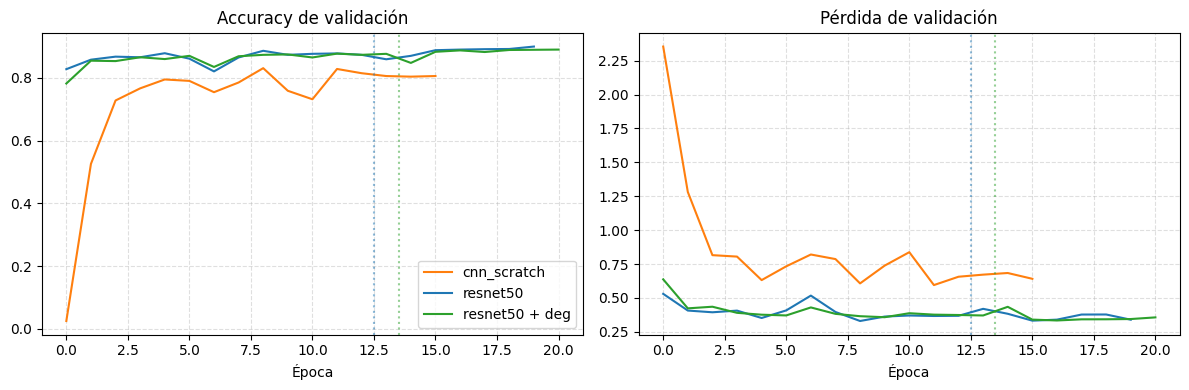

In [8]:
# Curvas REALES de validación (leídas de history.json), semilla 42
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
series = [('cnn_scratch', f"{BASE}/results", 'tab:orange'),
          ('resnet50', f"{BASE}/results", 'tab:blue'),
          ('resnet50 + deg', f"{BASE}/variants/deg/results", 'tab:green')]
for name, rdir, col in series:
    kind = name.split()[0]
    h = json.load(open(f"{rdir}/{kind}_seed{SEEDS[0]}/history.json"))['history']
    acc = sum([p['val_accuracy'] for p in h], []); loss = sum([p['val_loss'] for p in h], [])
    ax[0].plot(acc, color=col, label=name); ax[1].plot(loss, color=col, label=name)
    if kind == 'resnet50':
        for a_ in ax: a_.axvline(len(h[0]['val_loss']) - 0.5, ls=':', color=col, alpha=.5)
ax[0].set_title('Accuracy de validación'); ax[1].set_title('Pérdida de validación'); ax[0].legend()
for a_ in ax: a_.set_xlabel('Época'); a_.grid(ls='--', alpha=.4)
plt.tight_layout(); plt.savefig(f"{P['figures']}/curvas_entrenamiento.png", dpi=300); plt.show()

### Justificación de diseño (para el informe, sección 18.1)
- **ResNet50 preentrenada:** BRACOL es pequeño; los filtros de ImageNet (bordes, texturas, color) se transfieren a lesiones foliares. Las conexiones residuales permiten entrenar una red profunda sin degradación.
- **Dos fases:** primero se entrena solo la cabeza (lr 1e-3) y luego se descongela el último bloque (lr 1e-5) con BatchNorm congelada para no desestabilizar estadísticas con pocos datos.
- **Pérdida:** entropía cruzada categórica; **class weights** balanceados (razón ≈ 31:1 en train).
- **Preprocesamiento:** `preprocess_input` de ResNet50 dentro del modelo (no `1/255`).
- **Validación:** el conjunto val se usa para *early stopping* y para la decisión A/B; test y externo no participan en ninguna decisión.
- **Degradación de resolución:** variante probada porque el EDA mostró diferencias de nitidez entre BRACOL y JMuBEN; se adopta solo si mejora en val más que la variabilidad entre semillas.
- **Limitación:** la proporción de clases difiere entre splits (p. ej. Miner: 3.0 % en train frente a ~7 % en val y test) por usar los splits oficiales; se reporta, no se corrige.